# M3: Uji kasus sulit, etika, dan atribusi
IF25-40304 · Kelompok 09 · vegapunk

Menguji apakah sistem (encoder beku, baseline V0 dan terjemahan V2b dari M2) peka terhadap **atribut, negasi, penanda budaya, dan relasi**, dibanding **objek tunggal** (kontrol). Dua bagian: (A) **suite otomatis**: tiap caption diubah jadi versi salah, lalu dicek apakah gambar tetap lebih cocok dengan caption aslinya; (B) **5 kasus rinci** dengan probabilitas tiap kandidat. Bagian (C) menghitung keterwakilan penanda wilayah di caption untuk pernyataan etika.

**Cara pakai:** taruh di folder M3, atur `DIR` ke folder dataset dan `CACHE_BASE` ke cache M1/M2 bila cache tidak ada di M3, lalu **Run All**. Cache baseline yang diperlukan: `val_img.npy` dan `val_txt_id.npy`; cache train bersifat opsional. Tidak ada pelatihan; test set privat tidak disentuh; tidak ada yang disetel dengan melihat hasil. Perturbasi otomatis ditetapkan sebelum melihat skor, diturunkan dari caption yang sudah ada (bukan dataset baru, tanpa gambar baru) dan hanya untuk evaluasi diagnostik, bukan melatih atau menyetel; sebagian kecil hasilnya kurang gramatikal (catat di limitasi). **Verifikasi 5 kasus rinci dengan mata** (gambar ditampilkan).

Atribusi data: SEA-VL Indonesian subset (KORIKA-AI/sea-vl_crowdsourcing_id), diturunkan dari SEACrowd/sea-vl_crowdsourcing, lisensi CC BY-SA 4.0 (creativecommons.org/licenses/by-sa/4.0). Cahyawijaya et al. (2025), *Crowdsource, Crawl, or Generate? Creating SEA-VL, a Multicultural Vision-Language Dataset for Southeast Asia*, ACL.

In [1]:
import os, re, json, time, hashlib, platform, sys, textwrap
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
import sentence_transformers
from sentence_transformers import SentenceTransformer

DIR = "../bundle-mahasiswa"
SEED, SCALE, N_BOOT = 42, 100.0, 1000      # SCALE = logit scale CLIP (softmax atas kosinus)
KASUS_MANUAL = []   # opsional, maks 5: [(idx_pool, "tipe", "versi salah buatan sendiri"), ...]; idx_pool = nomor baris di pool (val dulu, lalu train). Kosong = pilih acak otomatis
PAKAI_MT = True                             # 5 kasus rinci juga diuji lewat terjemahan NLLB (V2b)
IMG_MODEL = "sentence-transformers/clip-ViT-B-32"
TXT_MODEL = "sentence-transformers/clip-ViT-B-32-multilingual-v1"
MT_MODEL  = "facebook/nllb-200-distilled-600M"
OUT = os.path.abspath("."); CACHE = f"{OUT}/cache"; CACHE_BASE = os.path.abspath(os.path.join(OUT, "..", "M2", "cache"))
os.chdir(DIR); os.makedirs(f"{OUT}/hasil", exist_ok=True); os.makedirs(CACHE, exist_ok=True)
np.random.seed(SEED); torch.manual_seed(SEED)
# [MODEL-LOAD]
txt_model = SentenceTransformer(TXT_MODEL, device="cpu")
img_model = SentenceTransformer(IMG_MODEL, device="cpu") if PAKAI_MT else None

C:\Multimodal_Tubes\Multimodal-Machine-Learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights:  13%|█▎        | 13/100 [00:00<00:00, 126.22it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 495.06it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   3%|▎         | 13/398 [00:00<00:03, 119.80it/s]

... (2 outputs left out)

Loading weights:  11%|█         | 42/398 [00:00<00:05, 61.16it/s]

Loading weights:  12%|█▏        | 49/398 [00:00<00:05, 60.06it/s]

Loading weights:  97%|█████████▋| 385/398 [00:00<00:00, 920.35it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 471.48it/s]

In [2]:
va = pd.read_csv("val.csv").assign(split="val"); tr = pd.read_csv("train.csv").assign(split="train")
CACHE_DATA = CACHE if all(os.path.exists(os.path.join(CACHE, n)) for n in ("val_img.npy", "val_txt_id.npy")) else CACHE_BASE
missing = [n for n in ("val_img.npy", "val_txt_id.npy") if not os.path.exists(os.path.join(CACHE_DATA, n))]
if missing: raise FileNotFoundError(f"Cache baseline tidak ditemukan: {missing}. Periksa CACHE atau CACHE_BASE ({CACHE_BASE}).")
Ev, Tv = np.load(os.path.join(CACHE_DATA, "val_img.npy")), np.load(os.path.join(CACHE_DATA, "val_txt_id.npy"))
if all(os.path.exists(os.path.join(CACHE_DATA, f"{n}.npy")) for n in ("train_img", "train_txt_id")):
    pool = pd.concat([va, tr], ignore_index=True)
    E, T = np.vstack([Ev, np.load(os.path.join(CACHE_DATA, "train_img.npy"))]), np.vstack([Tv, np.load(os.path.join(CACHE_DATA, "train_txt_id.npy"))])
else:
    pool, E, T = va, Ev, Tv; print("PERINGATAN: cache train tidak ada, suite hanya memakai val")
assert len(pool) == len(E) == len(T)
cap = pool["caption_id"].astype(str).tolist(); print("pool:", pool["split"].value_counts().to_dict(), "| cache:", CACHE_DATA)

PERINGATAN: cache train tidak ada, suite hanya memakai val
pool: {'val': 275} | cache: C:\Multimodal_Tubes\Multimodal-Machine-Learning\M2\cache


## A. Suite perturbasi otomatis
Setiap tipe mengubah **satu** hal pada caption yang benar. `objek` = kontrol (mengganti benda utama; seharusnya paling mudah). Kolom *Kata berubah* menunjukkan besar perubahan teks (pembanding adil antar tipe; `relasi` hanya mencakup pertukaran arah spasial sehingga n bisa kecil: anggap indikatif). Akurasi = proporsi gambar yang lebih cocok dengan caption asli daripada versi salah (acak = 0,5; tie dihitung salah).

In [3]:
WARNA = ["merah","biru","hijau","kuning","putih","hitam","ungu","oranye","coklat","emas"]
WIL = ["Jawa","Sunda","Bali","Minangkabau","Padang","Betawi","Bugis","Batak","Palembang","Madura","Yogyakarta","Solo","Aceh","Papua","Dayak","Toraja","Banyuwangi","Cirebon","Surabaya","Lombok","Medan","Semarang","Bandung"]
OBJ = [["sate","soto","bakso","nasi","mie","gudeg","rendang","lontong","pempek","gado-gado"],
       ["candi","masjid","gereja","pura","vihara","museum","rumah"], ["tari","wayang","gamelan","angklung","batik"]]
ANT = {"kiri":"kanan","kanan":"kiri","atas":"bawah","bawah":"atas","depan":"belakang","belakang":"depan"}

def _case(o, n): return n.capitalize() if o[:1].isupper() else n
def ganti_satu(t, kata, rng):                         # tepat satu kata dari daftar ada di caption -> ganti kata lain
    pat = re.compile(r"\b(" + "|".join(map(re.escape, kata)) + r")\b", re.I); ada = {m.lower() for m in pat.findall(t)}
    if len(ada) != 1: return None
    w = next(iter(ada)); baru = rng.choice([k for k in kata if k.lower() != w])
    return pat.sub(lambda m: _case(m.group(0), baru), t)
def p_atribut(t, r): return ganti_satu(t, WARNA, r)
def p_budaya(t, r): return ganti_satu(t, WIL, r)
def p_objek(t, r):
    for g in OBJ:
        x = ganti_satu(t, g, r)
        if x: return x
def p_negasi(t, r):
    if re.search(r"\btanpa\b", t, re.I): return None
    return re.sub(r"\b(dengan|memakai|pakai|berisi|membawa)\s+(?=\w)", "tanpa ", t, count=1, flags=re.I) if re.search(r"\b(dengan|memakai|pakai|berisi|membawa)\s+\w", t, re.I) else None
def p_relasi(t, r):
    pat = re.compile(r"\b(" + "|".join(ANT) + r")\b", re.I)
    return pat.sub(lambda m: _case(m.group(0), ANT[m.group(0).lower()]), t) if pat.search(t) else None
FN = {"objek": p_objek, "atribut": p_atribut, "budaya": p_budaya, "negasi": p_negasi, "relasi": p_relasi}

rows = []
for i, t in enumerate(cap):
    for k, (tipe, f) in enumerate(FN.items()):
        p = f(t, np.random.default_rng([SEED, i, k]))
        if p and p != t: rows.append({"idx": i, "split": pool["split"][i], "tipe": tipe, "asli": t, "pert": p})
S = pd.DataFrame(rows); print(S["tipe"].value_counts().to_dict())
H = hashlib.md5("\n".join(S["pert"]).encode()).hexdigest()[:8]; pc = f"{CACHE}/m3_pert_{H}.npy"
P = np.load(pc) if os.path.exists(pc) else txt_model.encode(S["pert"].tolist(), batch_size=64, normalize_embeddings=True)
np.save(pc, P)
ix = S["idx"].values; so, sp = (E[ix] * T[ix]).sum(1), (E[ix] * P).sum(1)
from difflib import SequenceMatcher
n_ubah = lambda a, b: sum(max(i2 - i1, j2 - j1) for t, i1, i2, j1, j2 in SequenceMatcher(None, a.split(), b.split()).get_opcodes() if t != "equal")
S["kata_berubah"] = [n_ubah(a, b) for a, b in zip(S["asli"], S["pert"])]
S["s_asli"], S["s_pert"], S["benar"] = so, sp, so > sp
S["p_asli"] = 1 / (1 + np.exp(-SCALE * (so - sp)))
S.to_csv(f"{OUT}/hasil/m3_suite_perturbasi.csv", index=False)

{'negasi': 101, 'objek': 79, 'budaya': 72, 'atribut': 29, 'relasi': 16}


,Tipe,n,Akurasi,CI95 bawah,CI95 atas,Kata berubah (rerata),P(asli) rerata,Margin kosinus,n val,Akurasi val
0,objek,79,0.658,0.557,0.759,1.380,0.627,0.008,79,0.658
1,atribut,29,0.517,0.345,0.690,1.000,0.583,0.006,29,0.517
2,budaya,72,0.625,0.514,0.736,1.097,0.600,0.008,72,0.625
3,negasi,101,0.663,0.574,0.752,1.000,0.556,0.003,101,0.663
4,relasi,16,0.562,0.312,0.812,1.188,0.505,0.000,16,0.562


objek − atribut : +0.141  CI95 [-0.060, +0.355]  → belum meyakinkan
objek − budaya  : +0.033  CI95 [-0.136, +0.181]  → belum meyakinkan
objek − negasi  : -0.005  CI95 [-0.143, +0.131]  → belum meyakinkan
objek − relasi  : +0.096  CI95 [-0.180, +0.371]  → belum meyakinkan


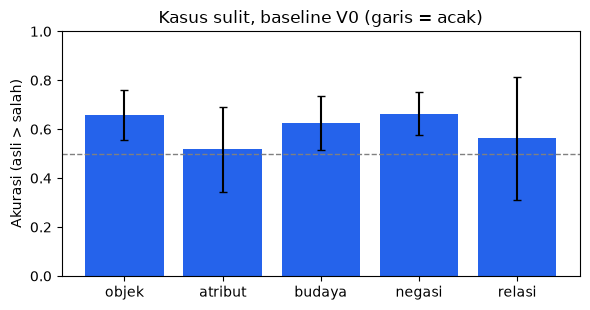

In [4]:
def boot(a, B=N_BOOT, seed=SEED):
    a = np.asarray(a, float); idx = np.random.default_rng(seed).integers(0, len(a), (B, len(a))); return np.percentile(a[idx].mean(1), [2.5, 97.5])
rows = []
for tipe in FN:
    g = S[S.tipe == tipe]
    if len(g) == 0: continue
    lo, hi = boot(g["benar"]); gv = g[g.split == "val"]
    rows.append({"Tipe": tipe, "n": len(g), "Akurasi": g["benar"].mean(), "CI95 bawah": lo, "CI95 atas": hi,
                 "Kata berubah (rerata)": g["kata_berubah"].mean(), "P(asli) rerata": g["p_asli"].mean(), "Margin kosinus": (g.s_asli - g.s_pert).mean(), "n val": len(gv), "Akurasi val": gv["benar"].mean() if len(gv) else np.nan})
R = pd.DataFrame(rows); R.round(4).to_csv(f"{OUT}/hasil/m3_akurasi_per_tipe.csv", index=False); display(R.round(3))

# objek tunggal (kontrol) vs hubungan/negasi: selisih akurasi + bootstrap tak berpasangan
a = S[S.tipe == "objek"]["benar"].values.astype(float)
for t in ("atribut", "budaya", "negasi", "relasi"):
    b = S[S.tipe == t]["benar"].values.astype(float)
    if len(a) and len(b):
        rg = np.random.default_rng(SEED); ia, ib = rg.integers(0, len(a), (N_BOOT, len(a))), rg.integers(0, len(b), (N_BOOT, len(b)))
        d = a[ia].mean(1) - b[ib].mean(1); lo, hi = np.percentile(d, [2.5, 97.5])
        print(f"objek − {t:8s}: {a.mean()-b.mean():+.3f}  CI95 [{lo:+.3f}, {hi:+.3f}]  → {'objek lebih mudah (meyakinkan)' if lo > 0 else 'belum meyakinkan'}")

fig, ax = plt.subplots(figsize=(6, 3.2)); y = R["Akurasi"].values
ax.bar(R["Tipe"], y, yerr=[y - R["CI95 bawah"], R["CI95 atas"] - y], color="#2563eb", capsize=3); ax.axhline(0.5, ls="--", c="gray", lw=1)
ax.set_ylabel("Akurasi (asli > salah)"); ax.set_ylim(0, 1); ax.set_title("Kasus sulit, baseline V0 (garis = acak)"); plt.tight_layout()
plt.savefig(f"{OUT}/hasil/m3_akurasi_per_tipe.png", dpi=160); plt.show()

## B. Lima kasus rinci
Satu kasus per tipe (negasi, atribut, penanda budaya, relasi, objek), dipilih acak (seed 42) dari val bila ada. Probabilitas = softmax(100 × kosinus) (100 ≈ logit scale CLIP). **Rancang kasusnya sendiri** bila bisa: isi `KASUS_MANUAL` (mis. “nasi padang dengan perkedel” vs “tanpa perkedel”); kosong = pilihan acak otomatis. **P(asli | gambar)**: dua kandidat teks untuk gambar itu. **5-arah**: query dibandingkan dengan kelima gambar. **Lihat gambarnya** untuk memastikan caption asli benar dan versi salah memang salah.

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 512/512 [00:00<00:00, 28444.25it/s]

[transformers] Both `max_new_tokens` (=160) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=160) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


,Tipe,Split,Caption asli,Versi salah,V0 P(asli|gambar),V0 P(gambar_i|query asli),V0 P(gambar_i|query salah),V0 top-1 gambar (query salah),V2b P(asli|gambar),V2b P(gambar_i|query asli),V2b P(gambar_i|query salah),V2b top-1 gambar (query salah)
0,negasi,val,Persawahan khas Bali dengan bangunan gubuk ata...,Persawahan khas Bali tanpa bangunan gubuk atau...,0.207,0.006,0.034,3,0.314,0.083,0.250,3
1,atribut,val,"Potongan kue lapis legit, yang dikenal dengan ...","Potongan kue lapis legit, yang dikenal dengan ...",0.770,1.000,1.000,2,0.706,1.000,1.000,2
2,budaya,val,Seorang wanita sedang berfoto di sekitar area ...,Seorang wanita sedang berfoto di sekitar area ...,0.934,1.000,0.992,3,0.503,1.000,1.000,3
3,relasi,val,"Semangkuk soto tegal, di atas taplak meja yang...","Semangkuk soto tegal, di bawah taplak meja yan...",0.408,0.897,0.966,4,0.569,0.982,0.983,4
4,objek,val,Warung soto lamongan di dekat Stasiun Pocin,Warung nasi lamongan di dekat Stasiun Pocin,0.671,0.947,0.419,1,1.000,0.999,0.000,1



Matriks 5-arah V0 (baris: 5 query asli lalu 5 query salah; kolom: gambar 1..5):


,g1,g2,g3,g4,g5
0,0.006,0.000,0.992,0.000,0.002
1,0.000,1.000,0.000,0.000,0.000
2,0.000,0.000,1.000,0.000,0.000
3,0.018,0.037,0.024,0.897,0.024
4,0.026,0.000,0.019,0.007,0.947
5,0.034,0.000,0.960,0.000,0.006
6,0.000,1.000,0.000,0.000,0.000
7,0.006,0.000,0.992,0.000,0.002
8,0.004,0.007,0.005,0.966,0.017
9,0.506,0.000,0.001,0.074,0.419


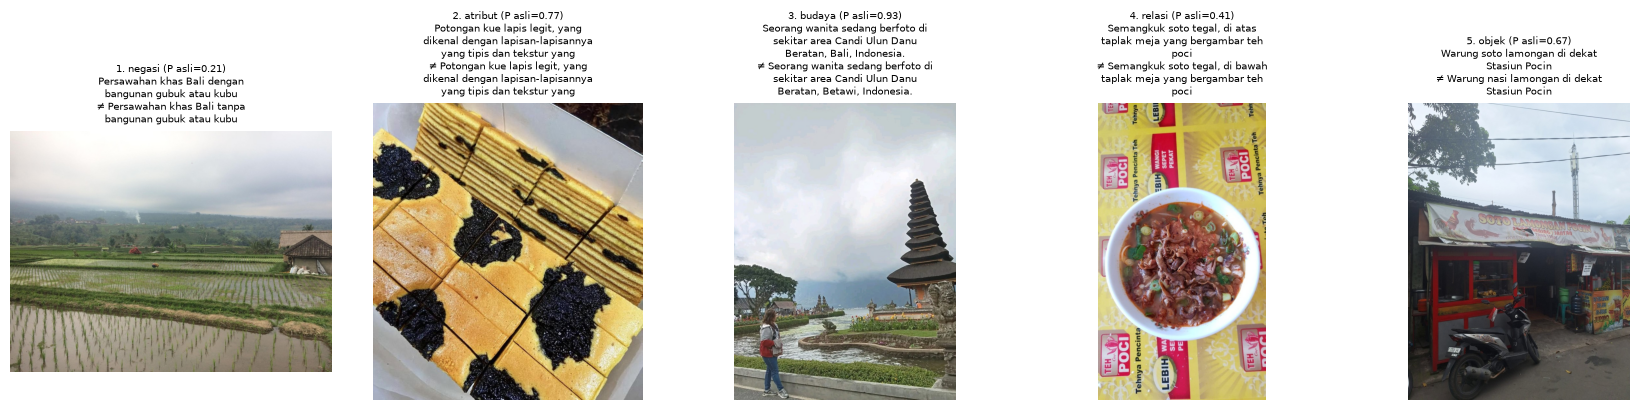

In [5]:
if KASUS_MANUAL:
    K5 = pd.DataFrame([{"idx": i, "tipe": t, "split": pool["split"][i], "asli": cap[i], "pert": p} for i, t, p in KASUS_MANUAL])
    P5 = txt_model.encode(K5["pert"].tolist(), batch_size=64, normalize_embeddings=True)
else:
    sel = []
    for k, tipe in enumerate(["negasi", "atribut", "budaya", "relasi", "objek"]):
        g = S[(S.tipe == tipe) & (S.split == "val")]; g = g if len(g) else S[S.tipe == tipe]
        if len(g): sel.append(g.iloc[int(np.random.default_rng([SEED, 99, k]).integers(len(g)))])
    K5 = pd.DataFrame(sel).reset_index(); P5 = P[K5["index"].values]
n5 = len(K5); assert n5 >= 1
E5 = E[K5["idx"].values]
tx = np.vstack([T[K5["idx"].values], P5])              # n teks asli, lalu n teks salah
soft = lambda s, ax: np.exp(SCALE * s - (SCALE * s).max(ax, keepdims=True)) / np.exp(SCALE * s - (SCALE * s).max(ax, keepdims=True)).sum(ax, keepdims=True)
def tabel(Sim, label):
    pair = soft(np.stack([Sim[np.arange(n5), np.arange(n5)], Sim[n5 + np.arange(n5), np.arange(n5)]], 1), 1)   # (n5,2): asli vs salah untuk gambar i
    five = soft(Sim, 1)                                                                                       # (2*n5, n5)
    return pd.DataFrame({"Tipe": K5["tipe"], "Split": K5["split"], "Caption asli": K5["asli"].str[:55], "Versi salah": K5["pert"].str[:55],
        f"{label} P(asli|gambar)": pair[:, 0].round(3), f"{label} P(gambar_i|query asli)": np.diag(five[:n5]).round(3),
        f"{label} P(gambar_i|query salah)": np.diag(five[n5:]).round(3), f"{label} top-1 gambar (query salah)": five[n5:].argmax(1) + 1})
Sim0 = tx @ E5.T; out = tabel(Sim0, "V0")
if PAKAI_MT:
    def terjemahkan(teks):   # [NLLB-LOAD]
        from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
        tok = AutoTokenizer.from_pretrained(MT_MODEL, src_lang="ind_Latn"); mt = AutoModelForSeq2SeqLM.from_pretrained(MT_MODEL).eval()
        bos = tok.convert_tokens_to_ids("eng_Latn"); o = []
        for i in range(0, len(teks), 8):
            e = tok(teks[i:i+8], return_tensors="pt", padding=True, truncation=True, max_length=200)
            with torch.no_grad(): g = mt.generate(**e, forced_bos_token_id=bos, num_beams=4, max_new_tokens=160)
            o += tok.batch_decode(g, skip_special_tokens=True)
        return o
    teks = list(K5["asli"]) + list(K5["pert"]); en = terjemahkan(teks)
    pd.DataFrame({"id": teks, "en_nllb": en}).to_csv(f"{OUT}/hasil/m3_terjemahan_lima_kasus.csv", index=False)
    Sim2 = img_model.encode(en, batch_size=16, normalize_embeddings=True) @ E5.T; out = out.join(tabel(Sim2, "V2b").iloc[:, 4:])
out.to_csv(f"{OUT}/hasil/m3_lima_kasus.csv", index=False); pd.set_option("display.width", 250, "display.max_columns", 30); display(out)
print("\nMatriks 5-arah V0 (baris: 5 query asli lalu 5 query salah; kolom: gambar 1..5):"); display(pd.DataFrame(soft(Sim0, 1).round(3), columns=[f"g{i+1}" for i in range(n5)]))

fig, axs = plt.subplots(1, n5, figsize=(3.4 * n5, 4.2))
for j, ax in enumerate(np.atleast_1d(axs)):
    r = K5.iloc[j]; ax.imshow(Image.open(pool["file"][r["idx"]]).convert("RGB")); ax.axis("off")
    ax.set_title(f"{j+1}. {r['tipe']} (P asli={out.iloc[j,4]:.2f})\n" + "\n".join(textwrap.wrap(r["asli"], 34)[:3]) + "\n≠ " + "\n".join(textwrap.wrap(r["pert"], 34)[:3]), fontsize=7.5)
plt.tight_layout(); plt.savefig(f"{OUT}/hasil/m3_lima_kasus.png", dpi=170); plt.show()

## C. Keterwakilan wilayah (untuk pernyataan etika 3b)
Kolom `loc` hanya mencatat negara, jadi keterwakilan daerah diperkirakan dari **penanda wilayah di caption** (pencarian kata kunci, bukan anotasi). Nol berarti tidak muncul di caption, bukan pasti tidak ada di data.

In [6]:
allcap = pd.concat([pd.read_csv("train.csv"), pd.read_csv("val.csv")], ignore_index=True)
ac = allcap["caption_id"].astype(str)
W = pd.DataFrame({"Penanda": WIL, "Caption": [int(ac.str.contains(rf"\b{re.escape(w)}\b", case=False, regex=True).sum()) for w in WIL]}).sort_values("Caption", ascending=False)
W["Persen dari caption"] = (W["Caption"] / len(ac) * 100).round(2); W.to_csv(f"{OUT}/hasil/m3_keterwakilan_wilayah.csv", index=False); display(W)
anyw = ac.str.contains("|".join(WIL), case=False, regex=True)
print(f"Caption dengan ≥1 penanda wilayah: {anyw.sum()} dari {len(ac)} ({anyw.mean()*100:.1f}%) | tiga teratas = {W.head(3)['Caption'].sum()/max(1,W['Caption'].sum())*100:.0f}% dari semua sebutan | penanda dengan 0 sebutan: {', '.join(W[W.Caption==0]['Penanda'])}")
print("loc:", allcap["loc"].value_counts(normalize=True).round(3).head(5).to_dict()); display(allcap["category"].value_counts().to_frame("gambar").assign(persen=lambda d: (d.gambar / len(allcap) * 100).round(1)))
print("Bahasa daerah dalam caption ID (contoh kata Jawa): ", int(ac.str.contains(r"\b(iki|wong|nggawe|sing|ora|karo|lan)\b", case=False, regex=True).sum()), "caption")

,Penanda,Caption,Persen dari caption
0,Jawa,162,6.90
2,Bali,97,4.13
10,Yogyakarta,80,3.41
22,Bandung,53,2.26
4,Padang,36,1.53
20,Medan,29,1.24
21,Semarang,22,0.94
1,Sunda,21,0.89
18,Surabaya,19,0.81
9,Madura,19,0.81


Caption dengan ≥1 penanda wilayah: 602 dari 2347 (25.6%) | tiga teratas = 52% dari semua sebutan | penanda dengan 0 sebutan: 
loc: {'Indonesia': 0.971, 'Indonesia, Malaysia': 0.009, 'Indonesia, Malaysia, Singapore': 0.008, 'Indonesia, Thailand': 0.002, 'Indonesia, Malaysia, Singapore, Thailand': 0.002}


,gambar,persen
category,,
kuliner,898,38.3
lain-lain,446,19.0
tarian,275,11.7
arsitektur/bangunan,203,8.6
wayang/seni,150,6.4
tempat/alam,146,6.2
pakaian/tekstil,105,4.5
flora/fauna,66,2.8
transportasi,34,1.4


Bahasa daerah dalam caption ID (contoh kata Jawa):  10 caption


C:\Users\mrsan\AppData\Local\Temp\ipykernel_28108\457956535.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  print("Bahasa daerah dalam caption ID (contoh kata Jawa): ", int(ac.str.contains(r"\b(iki|wong|nggawe|sing|ora|karo|lan)\b", case=False, regex=True).sum()), "caption")


In [7]:
print("Perangkat:", platform.platform(), "|", os.cpu_count(), "core | GPU:", torch.cuda.is_available())
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__, "| sentence-transformers", sentence_transformers.__version__)
print("Seed", SEED, "| bootstrap", N_BOOT, "| logit scale", SCALE, "| MT lima kasus:", PAKAI_MT)

Perangkat: Windows-11-10.0.26300-SP0 | 12 core | GPU: False
Python 3.12.10 | numpy 2.5.4 | torch 2.15.0+cpu | sentence-transformers 6.3.0
Seed 42 | bootstrap 1000 | logit scale 100.0 | MT lima kasus: True
